# 10 · Registered secondary analyses: DB, DL, OL (H5), Holm family, demand meta-regression

**Hierarchy (D4):**
- **Primary:** H1-WR, frozen and inconclusive.
- **Secondary, estimation:** H2, done.
- **This notebook:**
  - the **secondary Holm family** {H1-DB, H1-DL(a), H1-DL(b), H5(b)};
  - **estimation-only** H5(a), which is also the registered OL negative control N2;
  - H5(c) and H1-global;
  - **descriptive** H1-TE, used as a meta-regression input;
  - **exploratory** DL role subgroups.

It displays `scripts/run_secondary.py` (one run). No TE analysis beyond the registered descriptive estimates.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, polars as pl, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from nfl_bdb.visualization import style
style.apply(); pl.Config.set_tbl_rows(40); pl.Config.set_tbl_cols(20); pl.Config.set_fmt_str_lengths(60); pl.Config.set_tbl_width_chars(200)
RUN = (ROOT / 'experiments/secondary/LATEST').read_text().strip(); OUT = ROOT / 'experiments/secondary' / RUN
R = json.load(open(OUT / 'secondary_result.json')); BS = np.load(OUT / 'bootstraps.npz')
print('run', RUN, '| code commit', R['code_commit'], '| join', R['join_run'], '| frozen primary', R['primary_run'], '| B', R['B'], '| seeds', R['seeds'])

run 20261122T015315Z | code commit 18fca76a9b512f25add33505b9f2997d3ddffb4c | join 20261121T135032Z | frozen primary 20261121T223645Z | B 2000 | seeds {'DB': 8001, 'DL': 8002, 'OL': 8003, 'DLb': [8101, 8102, 8103, 8104], 'meta_boot': 8201}


## 1. Secondary Holm family (α = 0.05, m = 4; full REML player-cluster bootstrap, B = 2,000)

In [2]:
fam = R['family']
F = pl.DataFrame([dict(hypothesis=k, estimate=v['estimate'], ci95_lo=v['ci95'][0], ci95_hi=v['ci95'][1], ci90_hi=v['ci90'][1],
                       holm_step=v['holm_step'], holm_alpha=v['holm_alpha'], ci_holm_lo=v['ci_holm_level'][0], ci_holm_hi=v['ci_holm_level'][1],
                       p_unadjusted=v['p_unadjusted'], p_holm=v['p_holm'], decision=v['decision']) for k, v in fam.items()])
F

hypothesis,estimate,ci95_lo,ci95_hi,ci90_hi,holm_step,holm_alpha,ci_holm_lo,ci_holm_hi,p_unadjusted,p_holm,decision
str,f64,f64,f64,f64,i64,f64,f64,f64,f64,f64,str
"""H1-DB""",0.139449,-0.609248,1.050047,0.901378,2,0.016667,-0.820331,1.240138,0.691,1.0,"""INCONCLUSIVE"""
"""H1-DL(a)""",0.038016,-0.228718,0.153967,0.123568,4,0.05,-0.228718,0.153967,0.931,1.0,"""FALSIFIED"""
"""H1-DL(b)""",0.815829,0.160243,1.537563,1.476337,1,0.0125,0.030804,1.65903,0.008,0.032,"""SUPPORTED"""
"""H5(b)""",0.006455,-0.572855,0.627437,0.497913,3,0.025,-0.743699,0.739449,0.833,1.0,"""INCONCLUSIVE"""


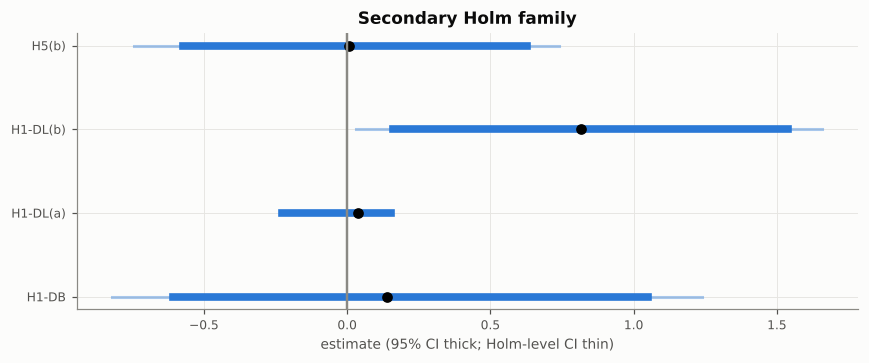

§9 sensitivity Holm over {H1-WR, H1-DB, H2}: {'names': ['H1-WR', 'H1-DB', 'H2'], 'p': [0.211, 0.691, 0.708], 'p_holm': [0.633, 1.0, 1.0], 'decisions': [False, False, False]}


In [3]:
fig, ax = plt.subplots(figsize=(8, 3.4))
for k, row in enumerate(F.iter_rows(named=True)):
    ax.plot([row['ci_holm_lo'], row['ci_holm_hi']], [k, k], color=style.SERIES[0], lw=2, alpha=0.4)
    ax.plot([row['ci95_lo'], row['ci95_hi']], [k, k], color=style.SERIES[0], lw=5)
    ax.plot(row['estimate'], k, 'o', color='k')
ax.axvline(0, color=style.MUTED); ax.set_yticks(range(F.height), F['hypothesis'])
ax.set_xlabel('estimate (95% CI thick; Holm-level CI thin)'); ax.set_title('Secondary Holm family')
fig.tight_layout(); fig.savefig(ROOT / 'reports/figures/secondary_family.png', dpi=150); plt.show()
print('§9 sensitivity Holm over {H1-WR, H1-DB, H2}:', R['holm_sensitivity_primary_family'])

## 2. Per-position fits (registered bivariate model; bootstrap test and delta-method Wald check)

In [4]:
rows = []
for p, t in R['tests'].items():
    w = R['wald'][f'{p}_full']; cov = np.array(w['cov']); se_d = float(np.sqrt(cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]))
    rows.append(dict(position=p, contexts=' vs '.join(t['plays_by_ctx']), players=t['players'], plays=t['plays'], team_seasons=t['team_seasons'],
                     rho_h=t['rho'][0], rho_l=t['rho'][1], delta=t['delta'], boot_ci95=str([round(v, 3) for v in t['ci95']]), boot_se=t['se_boot'],
                     wald_se=se_d, p=t['p'], raw_slope_h=t['beta'][0] * 0.25 / t['x_sd'], raw_slope_l=t['beta'][1] * 0.25 / t['x_sd'], converged=t['converged']))
display(pl.DataFrame(rows))
pl.DataFrame([dict(fit=k, contexts=str(v.get('contexts')), rho=str(np.round(v['rho'], 3).tolist()) if 'rho' in v else v.get('error'),
                   se=str(np.round(v['se'], 3).tolist()) if 'se' in v else '', players=v['players'], plays=v['plays']) for k, v in R['wald'].items()])

position,contexts,players,plays,team_seasons,rho_h,rho_l,delta,boot_ci95,boot_se,wald_se,p,raw_slope_h,raw_slope_l,converged
str,str,i64,i64,i64,f64,f64,f64,str,f64,f64,f64,f64,f64,bool
"""DB""","""man vs under_zone""",52,16643,69,0.289781,0.150332,0.139449,"""[-0.609, 1.05]""",0.415089,0.223427,0.691,0.057726,0.027807,true
"""DL""","""pass_rush vs run""",53,34154,69,0.568145,0.530129,0.038016,"""[-0.229, 0.154]""",0.095169,0.068884,0.931,0.088025,0.065592,true
"""OL""","""pass_block vs run""",53,64285,65,0.1085,0.025001,0.083499,"""[-0.457, 0.636]""",0.259317,0.156238,0.675,0.013579,0.003189,true


fit,contexts,rho,se,players,plays
str,str,str,str,i64,i64
"""WR_full""","""['deep', 'short']""","""[0.576, 0.486]""","""[0.096, 0.112]""",57,19960
"""TE_full""","""['deep', 'short']""","""[0.296, 0.213]""","""[0.274, 0.261]""",17,4170
"""DB_full""","""['man', 'under_zone']""","""[0.29, 0.15]""","""[0.172, 0.191]""",52,16643
"""DL_full""","""['pass_rush', 'run']""","""[0.568, 0.53]""","""[0.097, 0.112]""",53,34154
"""OL_full""","""['pass_block', 'run']""","""[0.108, 0.025]""","""[0.151, 0.156]""",53,64285
"""DB3_full""","""['man', 'deep_zone', 'under_zone']""","""[0.293, 0.091, 0.146]""","""[0.172, 0.176, 0.193]""",52,31164
"""DL_full_adjusted""","""['pass_rush', 'run']""","""[-0.181, -0.352]""","""[0.251, 0.236]""",53,34154
"""WR_halfA""","""['deep', 'short']""","""[0.408, 0.498]""","""[0.176, 0.175]""",28,11328
"""WR_halfB""","""['deep', 'short']""","""[0.644, 0.429]""","""[0.128, 0.17]""",29,8632


## 3. H1-DL(b): role sorting (registered) and exploratory role subgroups

pooled rho (mean of contexts): registered model 0.549 -> + alignment x context + combine weight x context -0.267
per context: base [0.568 0.53 ] | adjusted [-0.181 -0.352] | roles {'edge': 25, 'interior': 28} | bootstrap draws 2000


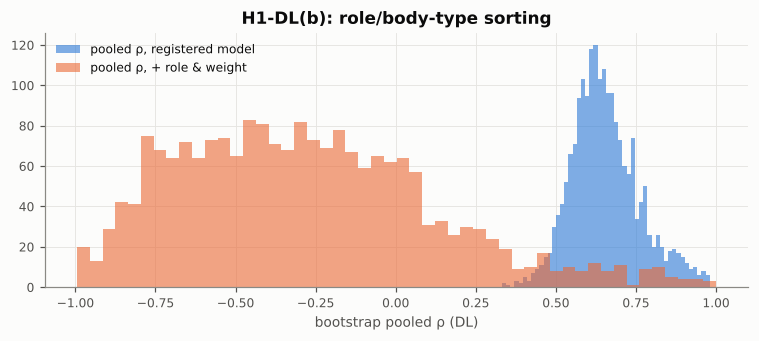

EXPLORATORY DL_EDGE_only rho [ 0.1   -0.009] Wald SE [0.242 0.254] players 25
EXPLORATORY DL_INTERIOR_LINE_only rho [0.002 0.011] Wald SE [0.213 0.226] players 28


In [5]:
b = R['dl_b']
print('pooled rho (mean of contexts): registered model %.3f -> + alignment x context + combine weight x context %.3f' % (b['base_pooled'], b['adjusted_pooled']))
print('per context: base', np.round(b['base_rho'], 3), '| adjusted', np.round(b['adjusted_rho'], 3), '| roles', b['roles'], '| bootstrap draws', b['boot_ok'])
dlb = BS['DLb']
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(dlb[:, 4], bins=50, alpha=0.6, color=style.SERIES[0], label='pooled ρ, registered model'); ax.hist(dlb[:, 5], bins=50, alpha=0.6, color=style.SERIES[1], label='pooled ρ, + role & weight')
ax.legend(); ax.set_xlabel('bootstrap pooled ρ (DL)'); ax.set_title('H1-DL(b): role/body-type sorting'); fig.tight_layout(); plt.show()
for k in ('DL_EDGE_only', 'DL_INTERIOR_LINE_only'):
    v = R['wald'][k]; print('EXPLORATORY', k, 'rho', np.round(v['rho'], 3), 'Wald SE', np.round(v['se'], 3), 'players', v['players'])

## 4. Offensive linemen: H5(a) = negative control N2, H5(b), H5(c)

In [6]:
print('H5(a) Δ_OL:', {k: (np.round(v, 3).tolist() if isinstance(v, list) else v) for k, v in R['h5a'].items()})
print('H5(b) Δ_WR − Δ_OL:', {k: fam['H5(b)'][k] for k in ('estimate', 'ci95', 'ci90', 'p_unadjusted', 'p_holm', 'decision')})
H = R['h5c']
display(pl.DataFrame([dict(swap=k, predicted=v['pred'], pi90_lo=v['pi90'][0], pi90_hi=v['pi90'][1], observed_pooled_OL=v['observed'], departure=v['departure'],
                           se_obs=v['se_obs'], se_fit=v['se_fit'], omega2=v['omega2'], lambda_noOL=v['lam_noOL'], D_OL=v['D_OL']) for k, v in H.items()]))
print('H5(c) reading:', H['averaged']['reading'], '| PI width', round(H['averaged']['pi_width'], 3))

H5(a) Δ_OL: {'delta': 0.08349878165711881, 'ci95': [-0.457, 0.636], 'ci90': [-0.315, 0.521], 'p': 0.675, 'consistent_with_demand_model': False}
H5(b) Δ_WR − Δ_OL: {'estimate': 0.006455093308879625, 'ci95': [-0.5728549990247107, 0.6274373336215135], 'ci90': [-0.4217303855506028, 0.49791251521332275], 'p_unadjusted': 0.833, 'p_holm': 1.0, 'decision': 'INCONCLUSIVE'}


swap,predicted,pi90_lo,pi90_hi,observed_pooled_OL,departure,se_obs,se_fit,omega2,lambda_noOL,D_OL
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""D_A_rho_B""",0.168853,-0.294627,0.632334,0.010974,-0.15788,0.182222,0.118555,0.000006,0.946693,0.007159
"""D_B_rho_A""",0.49365,0.021861,0.965438,0.124483,-0.369167,0.199827,0.095073,0.000006,0.222044,0.010522
"""averaged""",0.331251,-0.135354,0.797857,0.067728,-0.263523,0.191025,0.106814,0.000006,0.584368,0.008841


H5(c) reading: inside prediction interval | PI width 0.933


## 5. H1-global: cross-fitted demand meta-regression (estimation only) and TE (descriptive)

D_A_rho_B λ = 0.943 (SE 1.113), ω² = 0.0000, cell-bootstrap 95% CI [-5.77, 3.95]
D_B_rho_A λ = 0.225 (SE 1.227), ω² = 0.0000, cell-bootstrap 95% CI [-4.35, 8.2]
averaged λ: {'lam': 0.5841655503407921, 'lam_se': 1.1698481608702922}


pos,ctx,rho,se,D,players,swap
str,str,f64,f64,f64,i64,str
"""WR""","""deep""",0.644119,0.128281,0.179386,29,"""D:A / ρ:B"""
"""WR""","""short""",0.42855,0.170383,0.00427,29,"""D:A / ρ:B"""
"""TE""","""deep""",-0.302203,0.43651,0.22549,8,"""D:A / ρ:B"""
"""TE""","""short""",-0.119361,0.397836,0.028169,8,"""D:A / ρ:B"""
"""DB""","""man""",0.207949,0.272687,0.069257,24,"""D:A / ρ:B"""
"""DB""","""deep_zone""",0.036635,0.266369,0.027964,24,"""D:A / ρ:B"""
"""DB""","""under_zone""",0.114367,0.335177,0.013708,24,"""D:A / ρ:B"""
"""DL""","""pass_rush""",0.413921,0.171,0.024702,27,"""D:A / ρ:B"""
"""DL""","""run""",0.470151,0.169898,0.012725,27,"""D:A / ρ:B"""


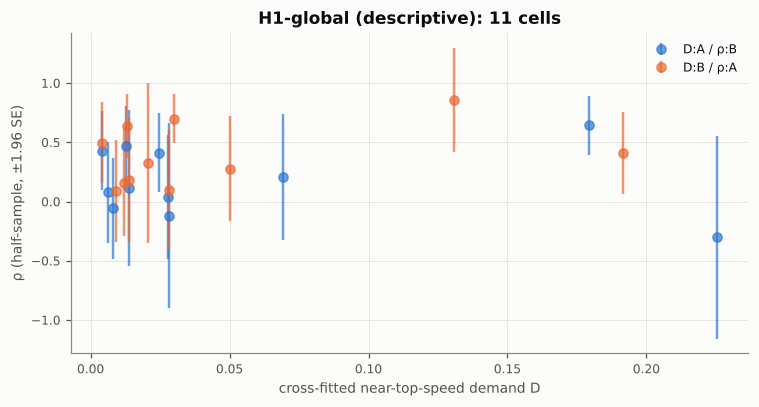

H1-TE (DESCRIPTIVE ONLY, n = 17): ρ_deep 0.296 (SE 0.274), ρ_short 0.213 (SE 0.261), Δ 0.083 (Wald SE 0.180)


In [7]:
G = R['h1_global']
for s in ('D_A_rho_B', 'D_B_rho_A'):
    print(s, 'λ = %.3f (SE %.3f), ω² = %.4f, cell-bootstrap 95%% CI %s' % (G[s]['lam'], G[s]['lam_se'], G[s]['omega2'], np.round(G[s]['lam_boot_ci95'], 2).tolist()))
print('averaged λ:', G['averaged'])
cells = pl.DataFrame(G['D_A_rho_B']['cells']).with_columns(pl.lit('D:A / ρ:B').alias('swap'))
cells = pl.concat([cells, pl.DataFrame(G['D_B_rho_A']['cells']).with_columns(pl.lit('D:B / ρ:A').alias('swap'))])
display(cells)
fig, ax = plt.subplots(figsize=(7, 3.8))
for k, (s, g) in enumerate(cells.group_by('swap', maintain_order=True)):
    ax.errorbar(g['D'], g['rho'], yerr=1.96 * g['se'], fmt='o', color=style.SERIES[k], alpha=0.7, label=s[0])
ax.set_xlabel('cross-fitted near-top-speed demand D'); ax.set_ylabel('ρ (half-sample, ±1.96 SE)'); ax.legend(); ax.set_title('H1-global (descriptive): 11 cells')
fig.tight_layout(); fig.savefig(ROOT / 'reports/figures/h1_global.png', dpi=150); plt.show()
w = R['wald']['TE_full']; cov = np.array(w['cov'])
print('H1-TE (DESCRIPTIVE ONLY, n = %d): ρ_deep %.3f (SE %.3f), ρ_short %.3f (SE %.3f), Δ %.3f (Wald SE %.3f)' %
      (w['players'], w['rho'][0], w['se'][0], w['rho'][1], w['se'][1], w['rho'][0] - w['rho'][1], np.sqrt(cov[0, 0] + cov[1, 1] - 2 * cov[0, 1])))

See `research_notes/secondary_family_results.md`, `db_secondary_results.md`, `dl_secondary_results.md` and `ol_secondary_results.md`.